# 3a. Co-occurrence vectors for codons

The simplest static embedding: describe each codon by **the codons around it**. For every codon type we
count how often each other codon appears within a half-window of ±k positions, across all 400 genomes. Each
row of the resulting 64 × 64 count matrix is a vector for one codon *type* — one vector, however many
different roles the codon plays.

This is the Zombienella 03a method applied to the Protocell-0 genome:

1. count matrices for half-windows ±1, ±2 and ±4 (Zombienella's "window 2, 4, 8");
2. cosine similarities between codon vectors;
3. PCA to two dimensions, for plotting.

Half-windows are always written ±k: ±1 means one codon on each side.

> **Proximity means similar contexts, not similar meaning.** Two codons end up close when they are surrounded
> by the same codons — whatever they code for.

*Run from `03-static/`.*

In [1]:
import sys, os, json, inspect
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

sys.path.insert(0, "..")
import protocell_lang as L

INPUT_FILE = "../data/corpus/genome.csv"
OUTPUT_FILE = "../data/web/cooccurrence.json"
NOTEBOOK = "03-static/03a_cooccurrence.ipynb"
HALF_WINDOWS = [1, 2, 4]
SEED = 42          # PCA is deterministic; the seed is recorded for the metadata block

## The corpus

Each genome is one sequence of codons (DNA alphabet). Windows never cross from one genome into the next.

In [2]:
genome = pd.read_csv(INPUT_FILE)
sequences = [g["codon"].tolist() for _, g in genome.sort_values(["genome_id", "position"]).groupby("genome_id")]
vocabulary = L.ALL_CODONS
print(f"{len(sequences)} genomes, {sum(map(len, sequences))} codons, vocabulary of {len(vocabulary)} codon types")
print("Codon types that never occur:", sorted(set(vocabulary) - set(genome["codon"])) or "none")

400 genomes, 97991 codons, vocabulary of 64 codon types
Codon types that never occur: none


## Build a co-occurrence matrix

For half-window ±k, each codon looks at up to k codons before it and k after it. Every (codon, neighbour) pair
adds one to the matrix.

In [3]:
def build_cooccurrence_matrix(sequences, vocabulary, half_window):
    index = {codon: i for i, codon in enumerate(vocabulary)}
    matrix = np.zeros((len(vocabulary), len(vocabulary)), dtype=int)
    for sequence in sequences:
        for i, codon in enumerate(sequence):
            start = max(0, i - half_window)
            end = min(len(sequence), i + half_window + 1)
            for j in range(start, end):
                if j != i:
                    matrix[index[codon], index[sequence[j]]] += 1
    return pd.DataFrame(matrix, index=vocabulary, columns=vocabulary)


matrices = {k: build_cooccurrence_matrix(sequences, vocabulary, k) for k in HALF_WINDOWS}
matrices[1].loc[["WXZ", "WXX", "WWX", "ZWW", "XZX", "YZX"], ["WXX", "WXZ", "WWX", "ZWW", "XZX", "YZX"]]

,WXX,WXZ,WWX,ZWW,XZX,YZX
WXZ,110,10,475,72,52,38
WXX,4732,110,74,201,82,92
WWX,74,475,14,18,121,101
ZWW,201,72,18,20,114,93
XZX,82,52,121,114,834,755
YZX,92,38,101,93,755,762


The rows of `WXX` (the RBS codon) and `WXZ` (the initiator) already show the grammar: at ±1, `WXZ`'s most
frequent neighbours are the gap codons and the gene markers, because a gene block reads
`RBS gap WXZ MARKER body …`.

## Cosine similarity

Two codon vectors are compared by the cosine of the angle between them: 1 means the same proportions of
neighbours, 0 means no neighbours in common.

In [4]:
def cosine_similarity_matrix(matrix):
    X = matrix.to_numpy(dtype=float)
    X = X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-12)
    return pd.DataFrame(X @ X.T, index=matrix.index, columns=matrix.index)


def nearest_neighbours(cosine, codon, n=5):
    return cosine[codon].drop(codon).sort_values(ascending=False).head(n)


cosines = {k: cosine_similarity_matrix(m) for k, m in matrices.items()}

PROBES = ["WXZ", "WXX", "WWX", "ZWW", "XZX", "YZX"]
rows = []
for k, cosine in cosines.items():
    for codon in PROBES:
        neighbours = nearest_neighbours(cosine, codon)
        rows.append({"half-window": f"±{k}", "codon": codon, "class": L.codon_class(codon),
                     "nearest neighbours (cosine)": ", ".join(f"{c} {v:.2f}" for c, v in neighbours.items())})
pd.DataFrame(rows)

,half-window,codon,class,nearest neighbours (cosine)
0,±1,WXZ,reserved,"YZZ 0.51, WYZ 0.49, YXW 0.48, XYZ 0.48, ZWY 0.47"
1,±1,WXX,reserved,"ZXX 0.91, WXW 0.90, ZYY 0.74, ZWY 0.74, YYZ 0.74"
2,±1,WWX,reserved,"WZX 0.94, WWY 0.94, WZY 0.93, WYX 0.93, WYY 0.92"
3,±1,ZWW,reserved,"XXZ 0.88, ZXX 0.88, XXW 0.87, WXW 0.87, ZWY 0.86"
4,±1,XZX,coding,"YZX 0.99, XYX 0.95, XZY 0.81, YYX 0.79, YZY 0.78"
5,±1,YZX,coding,"XZX 0.99, XYX 0.95, YZY 0.81, YYX 0.81, XZY 0.80"
6,±2,WXZ,reserved,"WWW 0.84, YZW 0.83, YXW 0.83, XYZ 0.82, ZXY 0.82"
7,±2,WXX,reserved,"ZXX 0.96, WXW 0.96, ZYY 0.94, YYZ 0.93, ZYX 0.93"
8,±2,WWX,reserved,"WWY 0.88, WZX 0.87, WYX 0.86, WZY 0.86, WXY 0.85"
9,±2,ZWW,reserved,"ZXX 0.91, WXW 0.90, XXW 0.89, WXX 0.89, XXZ 0.89"


What the table shows (seed 42):

- `XZX` and `YZX`, NaxGATE's preferred hydrophobic codons (Th and Lu, register X), are each other's nearest
  neighbour (cosine 0.99), followed by `XYX` (Kv, also preferred by NaxGATE). The gene's dialect is visible in
  the counts.
- `WWX`, NaxGATE's marker, is closest to the **other markers**, not to NaxGATE's body codons. All markers sit
  in the same slot (right after `WXZ`), and at these window sizes the slot matters more than the gene.
- `WXX`, the RBS codon, is closest to `ZXX` and `WXW` — exactly the codons a broken RBS mutates it into. They
  occupy the same slot, so they share contexts.
- `WXZ`, the initiator, has only weak neighbours at ±1 (cosine ≈ 0.5): its left context is a random gap codon
  and its right context is one of seven markers. It has **one** vector, built from true and false starts
  alike.
- At ±4 the terminator `ZWW` joins the markers and `WXZ`: gene punctuation forms its own neighbourhood.

## Two-dimensional view (PCA)

PCA finds the two directions along which the 64 count vectors vary most. It is only a way to draw them; the
vectors themselves are the matrix rows. Colours show each codon's class and, for coding codons, its preferred
gene (the gene whose dialect uses it most).

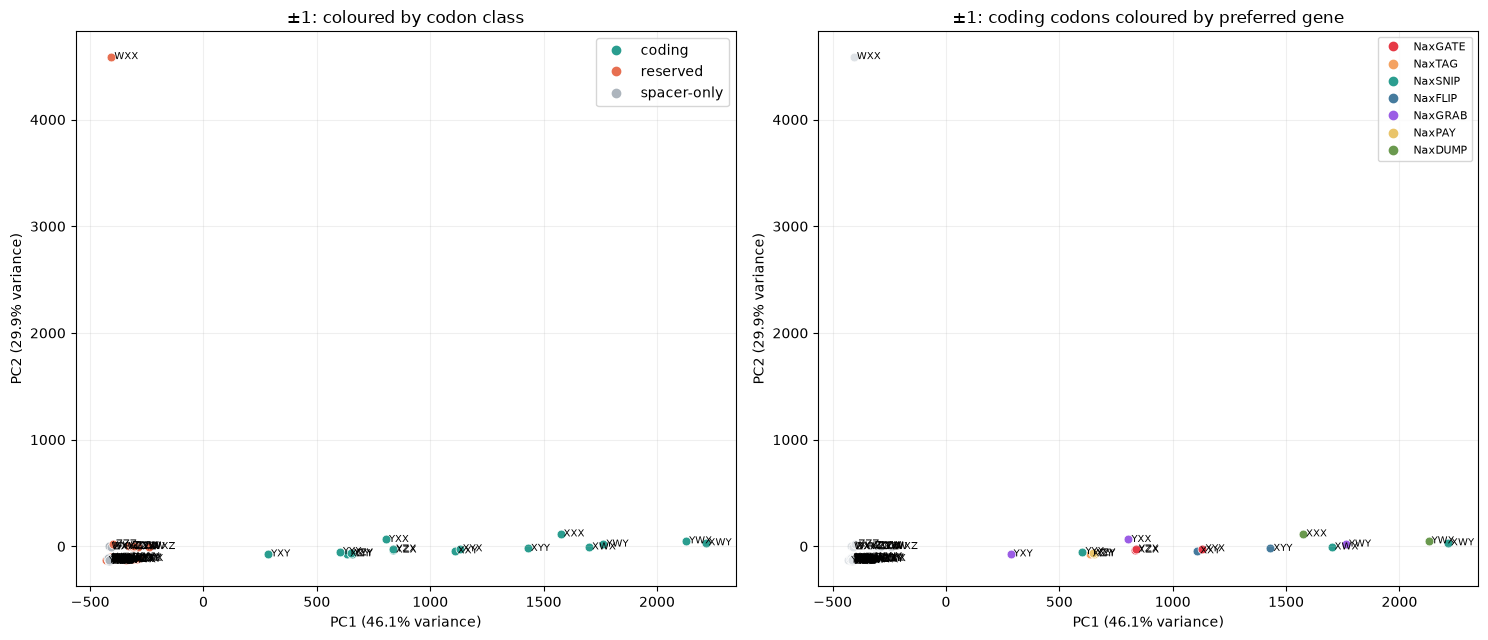

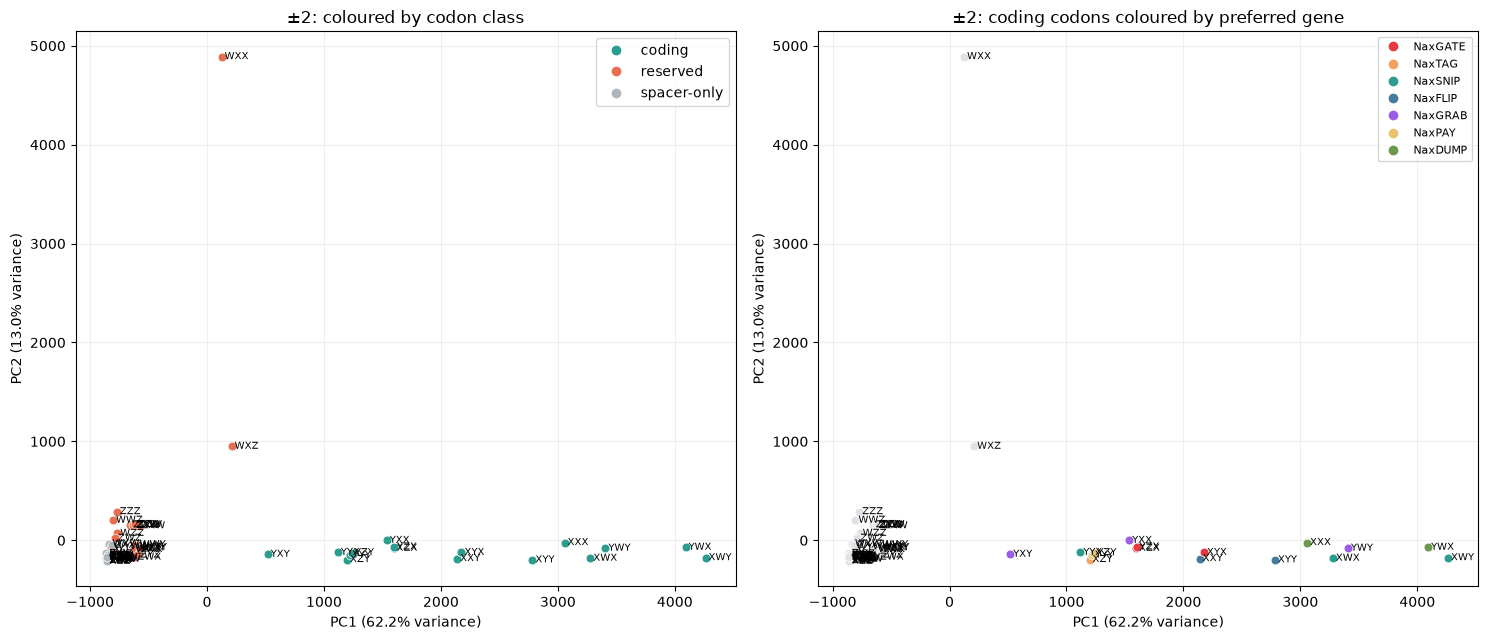

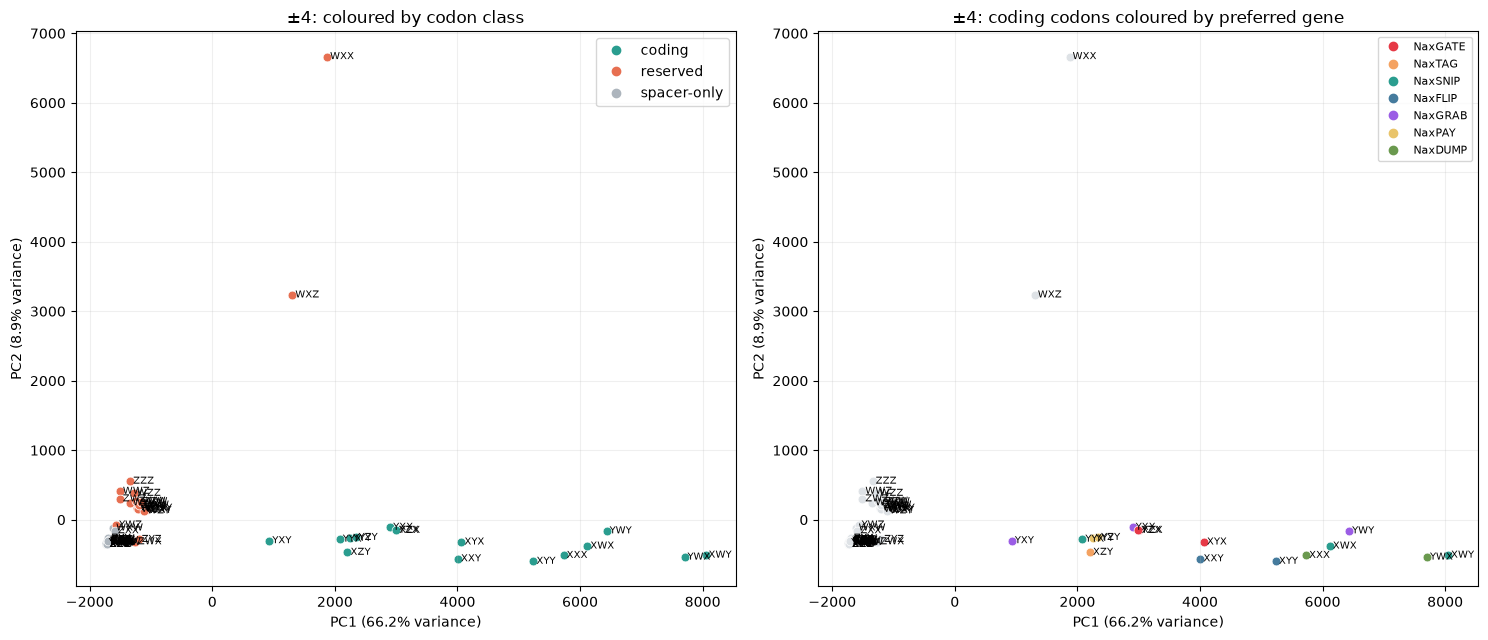

In [5]:
CLASS_COLOURS = {"coding": "#2a9d8f", "reserved": "#e76f51", "spacer-only": "#adb5bd"}
GENE_COLOURS = dict(zip(L.GENE_NAMES, ["#e63946", "#f4a261", "#2a9d8f", "#457b9d", "#9b5de5", "#e9c46a", "#6a994e"]))


def project_with_pca(matrix):
    pca = PCA(n_components=2)
    coordinates = pca.fit_transform(matrix.to_numpy(dtype=float))
    return pd.DataFrame(coordinates, index=matrix.index, columns=["PC1", "PC2"]), pca


def plot_codons(projected, pca, title, ax, colour_by="class"):
    for codon, (x, y) in projected.iterrows():
        if colour_by == "class":
            colour = CLASS_COLOURS[L.codon_class(codon)]
        else:
            gene = L.preferred_gene(codon)
            colour = GENE_COLOURS[gene] if gene and L.codon_class(codon) == "coding" else "#dee2e6"
        ax.scatter(x, y, s=40, color=colour, edgecolor="white", linewidth=0.5)
        ax.text(x, y, f" {codon}", fontsize=7, va="center")
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% variance)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% variance)")
    ax.set_title(title)
    ax.grid(True, alpha=0.2)


projections = {}
for k, matrix in matrices.items():
    projected, pca = project_with_pca(matrix)
    projections[k] = (projected, pca)
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
    plot_codons(projected, pca, f"±{k}: coloured by codon class", axes[0], "class")
    plot_codons(projected, pca, f"±{k}: coding codons coloured by preferred gene", axes[1], "gene")
    axes[0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=n) for n, c in CLASS_COLOURS.items()])
    axes[1].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=n) for n, c in GENE_COLOURS.items()], fontsize=8)
    fig.tight_layout()
    plt.show()

### What dominates PC1?

Raw counts mix two things: *which* neighbours a codon has, and *how often* the codon occurs. A frequent codon
has a long count vector. The next cell measures how strongly PC1 follows plain frequency.

In [6]:
frequency = genome["codon"].value_counts().reindex(vocabulary).fillna(0)
for k, (projected, pca) in projections.items():
    r = np.corrcoef(projected["PC1"], frequency)[0, 1]
    print(f"±{k}: correlation between PC1 and codon frequency = {r:+.2f}")

±1: correlation between PC1 and codon frequency = +0.89
±2: correlation between PC1 and codon frequency = +0.93
±4: correlation between PC1 and codon frequency = +0.96


With seed 42 the correlation is strong (about 0.9 or more at every window): PC1 mostly sorts codons by how
common they are. Coding codons are far more frequent than any spacer codon, because gene bodies make up most
of the genome. That is a property of raw counts, not of the language, so read the PCA plots with care. Cosine
similarity, which ignores vector length, is the fairer comparison, and it is what the tables above use.

## Export for the web labs

In [7]:
def round_list(array, decimals):
    return np.round(np.asarray(array, dtype=float), decimals).tolist()


payload = {
    "metadata": {
        "produced_by": NOTEBOOK,
        "function": build_cooccurrence_matrix.__name__,
        "source": inspect.getsource(build_cooccurrence_matrix),
        "seed": SEED,
        "params": {"half_windows": HALF_WINDOWS, "input": INPUT_FILE, "n_genomes": len(sequences)},
        "generator_version": L.GENERATOR_VERSION,
        "created": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    },
    "vocabulary": vocabulary,
    "codon_class": {c: L.codon_class(c) for c in vocabulary},
    "windows": [
        {"half_window": k,
         "counts": matrices[k].to_numpy().tolist(),
         "cosine": round_list(cosines[k].to_numpy(), 4),
         "pca": {"coords": round_list(projections[k][0].to_numpy(), 4),
                 "explained_variance": round_list(projections[k][1].explained_variance_ratio_, 4)}}
        for k in HALF_WINDOWS
    ],
}
with open(OUTPUT_FILE, "w", encoding="utf-8") as f:
    json.dump(payload, f, separators=(",", ":"))
print(f"Saved {OUTPUT_FILE} ({os.path.getsize(OUTPUT_FILE) / 1e6:.2f} MB)")

Saved ../data/web/cooccurrence.json (0.13 MB)


## Summary

- Each codon type gets one vector: the counts of its neighbours. The window decides what "context" means.
- Codons that the grammar puts in the same *slot* get similar vectors: coding codons with coding codons,
  markers with markers, the RBS codon with its broken-RBS mutants — even when they belong to different genes
  or classes.
- One vector per type cannot tell a true start from a false start: `WXZ` has a single row. Telling them
  apart needs a vector per *occurrence* — that is Part B.

Notebook 03b learns dense vectors from the same contexts with word2vec.